In [1]:
# From ref design
from pynq import Overlay
import xrfclk
from pynq import PL

# ADC
from adc_scope import AdcScope
import matplotlib.pyplot as plt
%matplotlib inline

# DAC
import numpy as np
from rfsoc_awg import *      # AWG, Pulse and the unit helpers ns, us, kHz, MHz, GHz

In [2]:
PL.reset()
xrfclk.set_ref_clks(lmk_freq=245.76, lmx_freq=491.52)   #Programs the oscillators on the board to produce the appropriate clock signals
ol = Overlay("awg_adc_v5.bit")         # after xrfclk.set_ref_clks(...) as usual

In [3]:
awg = AWG(window=25 * us, bitfile=ol) # 25us -> 40kHz min
sc = AdcScope(ol)                      # starts the ADC clock (MMCM) and checks the ADC streams

Window = 25.0000 us  (245760 samples, 15360 clock cycles)  [requested 25.0000 us]


DMA upload took 0.0077 s
Playing slot z on ['DAC_A', 'DAC_B']


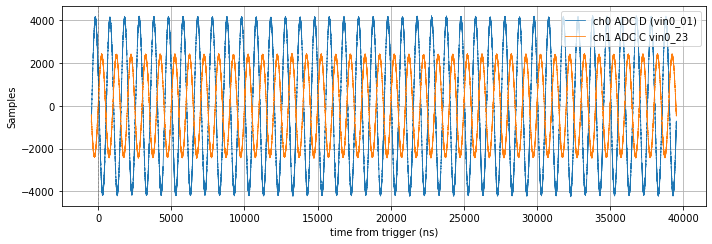

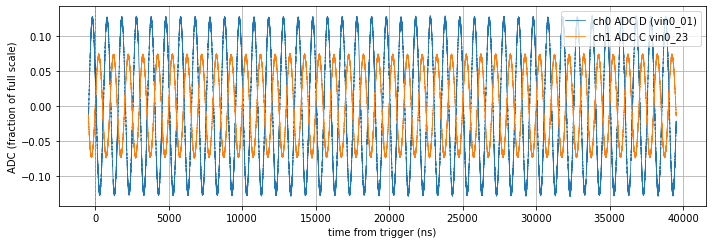

In [5]:
## Check input is connected
mysig = 0.2 * np.sin(2*np.pi*1e6*awg.t) 
awg.set_waveform("DAC_A", "x", mysig)
awg.set_waveform("DAC_B", "x", mysig)

awg.connect()    # load bitstream, program clocks, reset the AWG logic
awg.upload()     # send waveforms + length to the board RAM
awg.start()      # enable the outputs

sc.calibrate_awg0(channel=0)
sc.configure(trigger="awg0", length_ns=40000)
t, y = sc.acquire() # t in ns, 0 = trigger; y in fraction of full scale

sc.plot(t, y*32768.0, ylabel="Samples")
sc.plot(t, y)

[1.00000000e+05 2.15443469e+05 4.64158883e+05 1.00000000e+06
 2.15443469e+06 4.64158883e+06 1.00000000e+07 2.15443469e+07
 4.64158883e+07 1.00000000e+08]
20000
DMA upload took 0.0067 s
Playing slot z on ['DAC_A', 'DAC_B']
9283
DMA upload took 0.0065 s
Playing slot z on ['DAC_A', 'DAC_B']
4308
DMA upload took 0.0066 s
Playing slot z on ['DAC_A', 'DAC_B']
2000
DMA upload took 0.0066 s
Playing slot z on ['DAC_A', 'DAC_B']
928
DMA upload took 0.0066 s
Playing slot z on ['DAC_A', 'DAC_B']
430
DMA upload took 0.0065 s
Playing slot z on ['DAC_A', 'DAC_B']
200
DMA upload took 0.0066 s
Playing slot z on ['DAC_A', 'DAC_B']
92
DMA upload took 0.0066 s
Playing slot z on ['DAC_A', 'DAC_B']
43
DMA upload took 0.0066 s
Playing slot z on ['DAC_A', 'DAC_B']
20
DMA upload took 0.0066 s
Playing slot z on ['DAC_A', 'DAC_B']


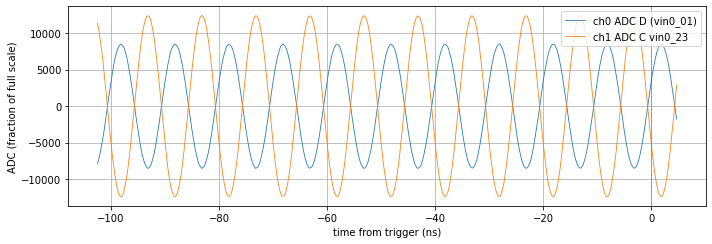

In [14]:
# My idea, but annoying to measure lower frequencies because we're limited with the nb of cycles. FFT needs at least 10 to be meaningful (arbitrary value, I just mean 2 is not good)
nbmeasurements = 10
log_increments = np.logspace(5, 8, num=nbmeasurements) # From 100k to 100M
print(log_increments)

CYCLES_TO_CAPTURE = 2

for i in range(nbmeasurements):
    freq = log_increments[i] 
    #print(f"--- Measurement {i+1}/{nbmeasurements} | Freq: {freq/1e6:.2f} MHz ---")
    period_sec = 1.0 / freq
    length_ns = int(CYCLES_TO_CAPTURE * period_sec * 1e9)
    print(length_ns)
    
    mysig = 0.2 * np.sin(2*np.pi*freq*awg.t) 
    awg.set_waveform("DAC_A", "x", mysig)
    awg.set_waveform("DAC_B", "x", mysig)
    awg.upload()     # send waveforms + length to the board RAM
    awg.start()      # enable the outputs
    sc.configure(trigger="immediate", length_ns=length_ns)
    
    t, y = sc.acquire(raw=True) # t in ns, 0 = trigger; y in fraction of full scale
    # sc.plot(t, y*32768.0, ylabel="Samples")
sc.plot(t, y) # Only plotting the last one

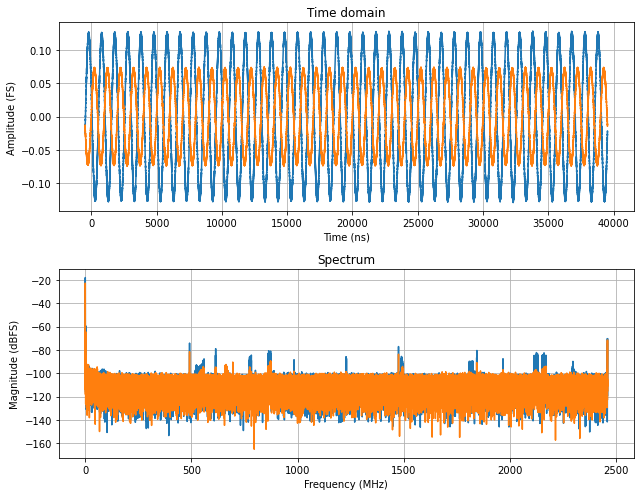

Peak: 1.000 MHz at -18.1 dBFS
Peak: 1.000 MHz at -22.8 dBFS


In [6]:
# Basic FFT of previous buffer, you get the peaks so you can make a bode
sigRC = y[0]  
sigBalun = y[1] 
t_s = t * 1e-9                 # ns -> s
dt = t_s[1] - t_s[0]           # sample period
N = len(sigRC)

# Remove DC and apply a window to reduce spectral leakage
sigRC = sigRC - np.mean(sigRC)
sigBalun = sigBalun - np.mean(sigBalun)
win = np.hanning(N)
sigRC_w = sigRC * win
sigBalun_w = sigBalun * win

# Real signal -> one-sided spectrum
spRC = np.fft.rfft(sigRC_w)
spBalun = np.fft.rfft(sigBalun_w)
freq = np.fft.rfftfreq(N, d=dt)   # Hz

# Amplitude scaling (corrects for window and one-sided spectrum)
magRC = 2 * np.abs(spRC) / np.sum(win)
magRC_db = 20 * np.log10(magRC + 1e-12)  # dB relative to full scale (dBFS)
magBalun = 2 * np.abs(spBalun) / np.sum(win)
magBalun_db = 20 * np.log10(magBalun + 1e-12)  # dB relative to full scale (dBFS)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7))

ax1.plot(t, y[0])
ax1.plot(t, y[1])
ax1.set_xlabel("Time (ns)")
ax1.set_ylabel("Amplitude (FS)")
ax1.set_title("Time domain")
ax1.grid(True)

ax2.plot(freq / 1e6, magRC_db)
ax2.plot(freq / 1e6, magBalun_db)
ax2.set_xlabel("Frequency (MHz)")
ax2.set_ylabel("Magnitude (dBFS)")
ax2.set_title("Spectrum")
ax2.grid(True)

plt.tight_layout()
plt.show()

# Print the strongest frequency component
peakRC = np.argmax(magRC[1:]) + 1
print(f"Peak: {freq[peakRC]/1e6:.3f} MHz at {magRC_db[peakRC]:.1f} dBFS")
peakBalun = np.argmax(magBalun[1:]) + 1
print(f"Peak: {freq[peakBalun]/1e6:.3f} MHz at {magBalun_db[peakBalun]:.1f} dBFS")

DMA upload took 0.0067 s
Playing slot z on ['DAC_A', 'DAC_B']
1/101 | set   0.0400 MHz | meas   0.0401 ± 0.0004 MHz | RC   32.5 ± 0.23 dBFS | Balun    4.7 ± 1.53 dBFS | Δphase   -40.1 ± 11.8°
DMA upload took 0.0067 s
Playing slot z on ['DAC_A', 'DAC_B']
2/101 | set   0.0443 MHz | meas   0.0466 ± 0.0184 MHz | RC   32.1 ± 0.83 dBFS | Balun   13.3 ± 4.95 dBFS | Δphase     9.8 ± 58.9°
DMA upload took 0.0066 s
Playing slot z on ['DAC_A', 'DAC_B']
3/101 | set   0.0490 MHz | meas   0.0353 ± 0.0303 MHz | RC   34.0 ± 3.01 dBFS | Balun   13.4 ± 5.81 dBFS | Δphase    -8.6 ± 81.1°
DMA upload took 0.0066 s
Playing slot z on ['DAC_A', 'DAC_B']
4/101 | set   0.0542 MHz | meas   0.1140 ± 0.1279 MHz | RC   34.5 ± 3.64 dBFS | Balun   15.9 ± 5.95 dBFS | Δphase    23.3 ± 85.0°
DMA upload took 0.0066 s
Playing slot z on ['DAC_A', 'DAC_B']
5/101 | set   0.0600 MHz | meas   0.0792 ± 0.0151 MHz | RC   39.1 ± 1.30 dBFS | Balun   10.3 ± 4.06 dBFS | Δphase   -42.5 ± 45.7°
DMA upload took 0.0066 s
Playing slot z 

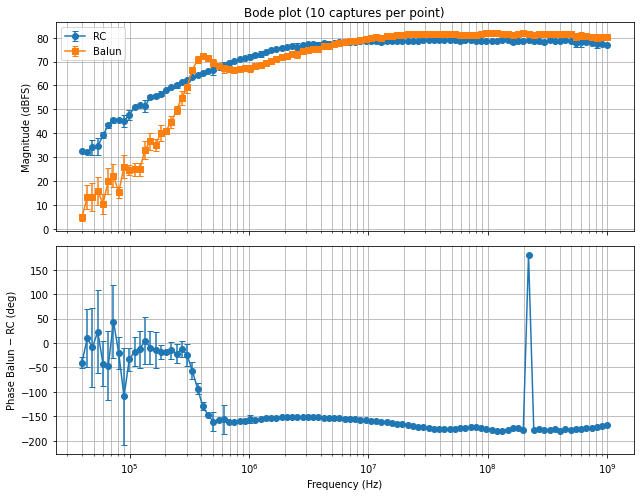

Saved 101 points to bode_sweep_loopback.csv


In [11]:
# Claude code handles repeats of 1 cycle
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import csv

MAX_LENGTH_NS = 25000     # scope buffer
MIN_LENGTH_NS = 1000      # don't capture less than this (avoids 10-sample captures at 100 MHz)
CYCLES = 1
N_REPEATS = 10

def sine_model(t, A, f, ph, c):
    return A * np.cos(2*np.pi*f*t + ph) + c

def fit_at_freq(t_s, sig, f):
    """Linear least-squares amplitude/phase at a fixed frequency."""
    w = 2 * np.pi * f
    M = np.column_stack([np.cos(w*t_s), np.sin(w*t_s), np.ones_like(t_s)])
    a, b, c = np.linalg.lstsq(M, sig, rcond=None)[0]
    return np.hypot(a, b), np.arctan2(-b, a), c

def fit_free_freq(t_s, sig, f_guess):
    """Free-frequency fit as a sanity check. Returns NaN if it fails."""
    A0, ph0, c0 = fit_at_freq(t_s, sig, f_guess)
    try:
        (A, f, ph, c), _ = curve_fit(sine_model, t_s, sig, p0=[A0, f_guess, ph0, c0])
        return abs(f)
    except RuntimeError:
        return np.nan

# --- Sweep ---
nbmeasurements = 101
test_freqs = np.logspace(np.log10(40e3), np.log10(1e9), num=nbmeasurements)   # 40 kHz to 1 GHz

ampRC_db,    ampRC_std    = np.zeros(nbmeasurements), np.zeros(nbmeasurements)
ampBalun_db, ampBalun_std = np.zeros(nbmeasurements), np.zeros(nbmeasurements)
dphase_deg,  dphase_std   = np.zeros(nbmeasurements), np.zeros(nbmeasurements)
f_meas,      f_meas_std   = np.zeros(nbmeasurements), np.zeros(nbmeasurements)

for i, f_test in enumerate(test_freqs):
    mysig = 0.2 * np.sin(2*np.pi*f_test*awg.t)
    awg.set_waveform("DAC_A", "x", mysig)
    awg.set_waveform("DAC_B", "x", mysig)
    awg.upload()
    awg.start()

    length_ns = int(CYCLES / f_test * 1e9)
    length_ns = min(max(length_ns, MIN_LENGTH_NS), MAX_LENGTH_NS)
    sc.configure(trigger="immediate", length_ns=length_ns)

    aRC, aBal, dph, fm = [], [], [], []
    for r in range(N_REPEATS):
        t, y = sc.acquire(raw=True)
        t_s = t * 1e-9

        A1, ph1, _ = fit_at_freq(t_s, y[0], f_test)
        A2, ph2, _ = fit_at_freq(t_s, y[1], f_test)
        aRC.append(A1)
        aBal.append(A2)
        dph.append(ph2 - ph1)
        fm.append(fit_free_freq(t_s, y[0], f_test))

    aRC, aBal, dph, fm = map(np.array, (aRC, aBal, dph, fm))

    # Amplitude: mean and spread, in dB
    ampRC_db[i]    = 20*np.log10(aRC.mean())
    ampBalun_db[i] = 20*np.log10(aBal.mean())
    ampRC_std[i]    = 20*np.log10(1 + aRC.std()  / aRC.mean())
    ampBalun_std[i] = 20*np.log10(1 + aBal.std() / aBal.mean())

    # Phase difference: circular mean and spread
    z = np.exp(1j*dph)
    dphase_deg[i] = np.degrees(np.angle(z.mean()))
    dphase_std[i] = np.degrees(np.sqrt(-2*np.log(np.abs(z.mean()))))

    f_meas[i], f_meas_std[i] = np.nanmean(fm), np.nanstd(fm)

    print(f"{i+1}/{nbmeasurements} | set {f_test/1e6:8.4f} MHz | "
          f"meas {f_meas[i]/1e6:8.4f} ± {f_meas_std[i]/1e6:.4f} MHz | "
          f"RC {ampRC_db[i]:6.1f} ± {ampRC_std[i]:.2f} dBFS | "
          f"Balun {ampBalun_db[i]:6.1f} ± {ampBalun_std[i]:.2f} dBFS | "
          f"Δphase {dphase_deg[i]:7.1f} ± {dphase_std[i]:.1f}°")

# --- Bode plot with error bars ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

ax1.errorbar(test_freqs, ampRC_db, yerr=ampRC_std, fmt="o-", capsize=3, label="RC")
ax1.errorbar(test_freqs, ampBalun_db, yerr=ampBalun_std, fmt="s-", capsize=3, label="Balun")
ax1.set_xscale("log")
ax1.set_ylabel("Magnitude (dBFS)")
ax1.set_title(f"Bode plot ({N_REPEATS} captures per point)")
ax1.legend()
ax1.grid(True, which="both")

# Idk if this is meaningful. We do immediate measurements, not triggered or calibrated.
ax2.errorbar(test_freqs, dphase_deg, yerr=dphase_std, fmt="o-", capsize=3)
ax2.set_xscale("log")
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Phase Balun − RC (deg)")
ax2.grid(True, which="both")

plt.tight_layout()
plt.show()

path = "bode_sweep_loopback.csv"
rows = zip(test_freqs, f_meas, f_meas_std,
           ampRC_db, ampRC_std,
           ampBalun_db, ampBalun_std,
           dphase_deg, dphase_std)
with open(path, "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["freq_set_hz", "freq_meas_hz", "freq_meas_std_hz",
                "ampRC_dbfs", "ampRC_std_db",
                "ampBalun_dbfs", "ampBalun_std_db",
                "dphase_deg", "dphase_std_deg"])
    w.writerows(sorted(rows, key=lambda r: (np.isnan(r[0]), r[0])))

print(f"Saved {len(test_freqs)} points to {path}")

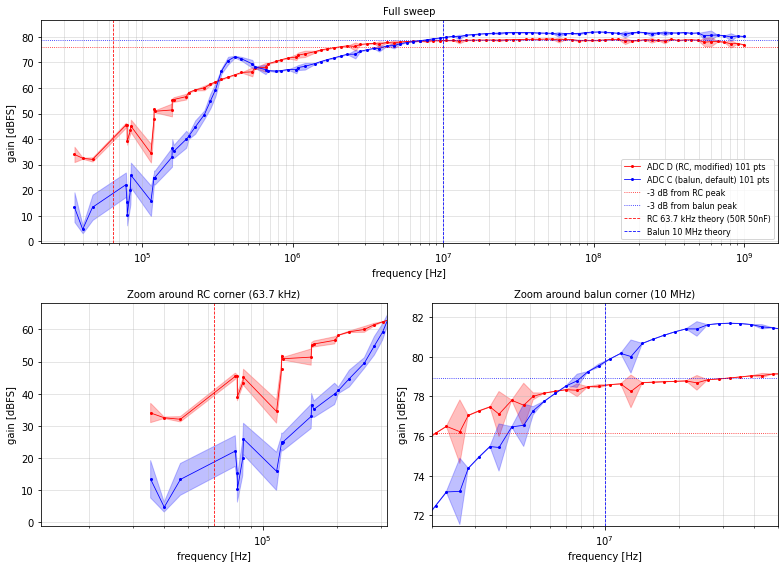

RC -3 dB: 76.14 dBFS
Balun -3 dB: 78.91 dBFS
Difference: 2.77 dB


In [20]:
data = np.genfromtxt("bode_sweep_loopback.csv", delimiter=",", names=True, dtype=None, encoding="utf-8")
f = data["freq_meas_hz"].astype(float)

def load(col):
    g, gs = data[f"{col}_dbfs"].astype(float), data[f"{col}_std_db"].astype(float)
    ok = np.isfinite(f) & np.isfinite(g)
    o = np.argsort(f[ok])
    return f[ok][o], g[ok][o], gs[ok][o]

f_rc, g_rc, gs_rc = load("ampRC")
f_bl, g_bl, gs_bl = load("ampBalun")
pk_rc, pk_bl = g_rc.max(), g_bl.max()

fc_rc = 1 / (2 * np.pi * 50 * 50e-9)   # ~63.7 kHz
fc_bl = 10e6
span = 5                               # zoom window = fc/span … fc*span

def draw(ax):
    ax.semilogx(f_rc, g_rc, ".-", ms=4, lw=0.8, color="r", label=f"ADC D (RC, modified) {len(f_rc)} pts")
    ax.fill_between(f_rc, g_rc - gs_rc, g_rc + gs_rc, alpha=0.25, color="r")
    ax.semilogx(f_bl, g_bl, ".-", ms=4, lw=0.8, color="b", label=f"ADC C (balun, default) {len(f_bl)} pts")
    ax.fill_between(f_bl, g_bl - gs_bl, g_bl + gs_bl, alpha=0.25, color="b")
    ax.axhline(pk_rc - 3, color="r", ls=":", lw=0.8, label="-3 dB from RC peak")
    ax.axhline(pk_bl - 3, color="b", ls=":", lw=0.8, label="-3 dB from balun peak")
    ax.axvline(fc_rc, color="r", ls="--", lw=0.8, label=f"RC {fc_rc/1e3:.1f} kHz theory (50R 50nF)")
    ax.axvline(fc_bl, color="b", ls="--", lw=0.8, label="Balun 10 MHz theory")
    ax.grid(True, which="both", alpha=0.4)

def zoom(ax, fc, title):
    lo, hi = fc / span, fc * span
    ax.set_xlim(lo, hi)
    ys = [y for x, y in ((f_rc, g_rc), (f_bl, g_bl)) for y in [y[(x >= lo) & (x <= hi)]] if y.size]
    if ys:
        ys = np.concatenate(ys)
        pad = 0.1 * (ys.max() - ys.min() + 1)
        ax.set_ylim(ys.min() - pad, ys.max() + pad)
    ax.set_title(title, fontsize=10)

fig = plt.figure(figsize=(11, 8))
gsp = fig.add_gridspec(2, 2, height_ratios=[1, 1])
ax_full = fig.add_subplot(gsp[0, :])
ax_rc   = fig.add_subplot(gsp[1, 0])
ax_bl   = fig.add_subplot(gsp[1, 1])

for a in (ax_full, ax_rc, ax_bl):
    draw(a)
ax_full.set_title("Full sweep", fontsize=10)
ax_full.legend(fontsize=8, loc="best")
zoom(ax_rc, fc_rc, f"Zoom around RC corner ({fc_rc/1e3:.1f} kHz)")
zoom(ax_bl, fc_bl, "Zoom around balun corner (10 MHz)")

for a in (ax_full, ax_rc, ax_bl):
    a.set_xlabel("frequency [Hz]"); a.set_ylabel("gain [dBFS]")
fig.tight_layout()
plt.show()

print(f"RC -3 dB: {pk_rc - 3:.2f} dBFS\nBalun -3 dB: {pk_bl - 3:.2f} dBFS\nDifference: {pk_bl - pk_rc:.2f} dB")

In [13]:
# import numpy as np
# import matplotlib.pyplot as plt

# # ==============================================================================
# # 🛠️ CORE MATHEMATICAL FUNCTIONS (From bode_point.py)
# # ==============================================================================
# def _fit(t_s, y, f):
#     """Sine fit at known f using 3x3 normal equations."""
#     w = (2 * np.pi * f) * t_s
#     sn, cs = np.sin(w), np.cos(w)
#     n = float(len(y))
#     G = np.array([[sn @ sn, sn @ cs, sn.sum()], 
#                   [sn @ cs, cs @ cs, cs.sum()], 
#                   [sn.sum(), cs.sum(), n]])
#     a, b, c = np.linalg.solve(G, np.array([sn @ y, cs @ y, y.sum()]))
#     r = y - (a * sn + b * cs + c)
#     return float(np.hypot(a, b)), float(np.sqrt(np.mean(r * r)))

# # ==============================================================================
# # 🎛️ CONFIGURATION & SWEEP SETUP
# # ==============================================================================
# nbmeasurements = 9
# log_increments = np.logspace(5, 8, num=nbmeasurements)  # 100 kHz to 100 MHz
# print("Frequencies to scan (Hz):", log_increments)

# sc.calibrate_awg0(channel=0)

# CYCLES_TO_CAPTURE = 4
# MAX_AWG_WINDOW_NS = 25000  # Hard hardware buffer limit
# GEN_VPK = 0.2              # Your sine wave generation peak amplitude
# ADC_VFS = 1.0              # Volts peak for 1.0 Full Scale (adjust to your board)
# THRESHOLD = 0.005          # Drop points below this amplitude

# # Lists to store our final processed Bode trace data
# bode_frequencies = []
# bode_gains_db = []

# # ==============================================================================
# # 🔄 EXECUTION LOOP (One Graph & Point Per Step)
# # ==============================================================================
# for i in range(nbmeasurements):
#     freq = log_increments[i]
#     print(f"\n--- Measurement {i+1}/{nbmeasurements} | Target Freq: {freq/1e6:.2f} MHz ---")
    
#     # 1. Calculate and clamp the window length to hardware limits
#     period_sec = 1.0 / freq
#     ideal_length_ns = int(CYCLES_TO_CAPTURE * period_sec * 1e9)
#     length_ns = min(ideal_length_ns, MAX_AWG_WINDOW_NS)
#     length_ns = max(length_ns, 20)
    
#     sc.configure(trigger="awg0", length_ns=length_ns)
    
#     # 2. Re-generate signal, upload, and run
#     awg.stop()
#     mysig = GEN_VPK * np.sin(2 * np.pi * freq * awg.t) 
#     awg.set_waveform("DAC_A", "x", mysig)
#     awg.set_waveform("DAC_B", "x", mysig)
#     awg.upload()     
#     awg.start()      
    
#     # 3. Data Acquisition
#     sc.calibrate_awg0(channel=0)
#     t, y = sc.acquire()  # t in ns, y in fraction of full scale
    
#     # 4. Filter and Fit Math
#     t_s = np.asarray(t, float) * 1e-9  # Convert ns to seconds for math consistency
#     y_arr = np.asarray(y, float)
    
#     # If scope returns multiple channels, select channel 0 (or your target)
#     if y_arr.ndim > 1:
#         y_arr = y_arr[0] 
        
#     # Fit the sine wave at the exact generated frequency
#     amp_fs, resid = _fit(t_s, y_arr, freq)
    
#     # Check flags
#     clip = bool(np.max(np.abs(y_arr)) > 0.95)
#     ok = amp_fs >= THRESHOLD and not clip and resid < 0.3 * amp_fs
    
#     # Calculate Gain relative to target
#     gain_db = 20 * np.log10(max(amp_fs, 1e-12) * ADC_VFS / GEN_VPK)
    
#     # Output real-time stats to terminal
#     note = "" if ok else (" [CLIPPING]" if clip else " [BELOW THRESHOLD / POOR FIT]")
#     print(f"Measured: {freq/1e6:10.4f} MHz | Amp: {amp_fs:.4f} FS | Gain: {gain_db:+.2f} dB{note}")
    
#     if ok:
#         bode_frequencies.append(freq)
#         bode_gains_db.append(gain_db)
    
#     # 5. Plot the current time-domain waveform
#     clean_mask = np.ones_like(t, dtype=bool)
#     sc.plot(t[clean_mask], y_arr[clean_mask], ylabel="Fraction of Full Scale")

# # ==============================================================================
# # 📊 FINAL PLOTTING & EXPORT
# # ==============================================================================
# print("\n--- Sweep Completed. Rendering Bode Plot... ---")

# # Save Trace to CSV file
# import csv
# with open("bodeLogADC_C.csv", "w", newline="") as f:
#     writer = csv.writer(f)
#     writer.writerow(["Frequency (Hz)", "Gain (dB)"])
#     writer.writerows(zip(bode_frequencies, bode_gains_db))
# print("Bode data safely stored in 'bodeLogADC_C.csv'")

# # Generate beautiful custom Bode graph
# plt.figure(figsize=(10, 5))
# plt.semilogx(bode_frequencies, bode_gains_db, 'o-', color='C0', linewidth=2, label="CH0 Gain")
# plt.grid(True, which="both", linestyle="--", alpha=0.7)
# plt.xlabel("Frequency (Hz)")
# plt.ylabel("Gain (dB)")
# plt.title("Bode Frequency Response (ADC D)")
# plt.legend()
# plt.show()
